# HW2 Part 1 — Data Cleaning & Validation

**Goal:** turn the intentionally dirty `ohlc_hw` table into a validated `ohlc_hw_cleaned` table that the
risk report (Part 2) can trust.

Workflow, following the assignment order:

| Section | What happens |
|---|---|
| 1.1 Load and inspect | types, statistics, column meanings, date range, tickers |
| 1.2 Detect | ticker labels, duplicates, missing cells, missing sessions, return outliers, impossible / inconsistent prices, zero volume → **Data Quality Report** |
| 1.3 Clean | drop all-missing rows, rebuild adjusted close, repair invalid rows, fill unknown volume, investigate outliers, quarantine |
| Validation | required checks, post-repair diagnosis, before/after statistics, row accounting, save and read back |

The cleaning logic lives in `hw2_cleaning.py` (pure functions with unit tests in `tests/`). This notebook
calls those functions, shows the evidence behind each decision, and writes the results.

**Inputs:** `data/data.db` — a local *working copy* of the bCourses database (never committed).
The raw `ohlc_hw` table is read-only here; it is fingerprinted before and after to prove it is unchanged.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import hw2_cleaning as hc

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

DB_PATH = Path("data/data.db")  # working copy, relative to this homework folder
if not DB_PATH.is_file():
    raise FileNotFoundError(f"Copy the bCourses data.db to {DB_PATH.resolve()} before running.")


def read_only(path):
    """Open SQLite in read-only mode so inspection can never modify the database."""
    return sqlite3.connect(Path(path).resolve().as_uri() + "?mode=ro", uri=True)

## 1.1 Load and inspect the data

`ohlc_hw` is the dirty homework table. `ohlc` is the supplied reference table; the assignment allows it
as a **reference calendar** (which dates each ticker should have) and as a source of **date-specific
adjustment factors**. It is never used to replace the dirty data wholesale.

`raw_rowid` (SQLite's row id) is loaded so every cleaned or quarantined row can be traced back to the
exact raw record.

In [2]:
with closing(read_only(DB_PATH)) as conn:
    display(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn))
    raw = pd.read_sql_query("SELECT rowid AS raw_rowid, * FROM ohlc_hw", conn)
    reference = pd.read_sql_query("SELECT * FROM ohlc", conn)

# Fingerprint of the raw table, re-checked after writing to prove ohlc_hw was not modified.
raw_fingerprint = int(pd.util.hash_pandas_object(raw, index=False).sum())
print(f"ohlc_hw: {len(raw):,} rows | ohlc (reference): {len(reference):,} rows")

,name
0,market_caps
1,ohlc
2,ohlc_hw
3,ohlc_hw_cleaned
4,ohlc_hw_quality_report
5,ohlc_hw_quarantine


ohlc_hw: 397,711 rows | ohlc (reference): 368,251 rows


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 9 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   raw_rowid  397711 non-null  int64  
 1   ts         397711 non-null  str    
 2   open       397711 non-null  float64
 3   high       397711 non-null  float64
 4   low        397711 non-null  float64
 5   close      397711 non-null  float64
 6   adj_close  377856 non-null  float64
 7   volume     397711 non-null  int64  
 8   ticker     397711 non-null  str    
dtypes: float64(5), int64(2), str(2)
memory usage: 34.7 MB


In [4]:
raw.describe()

,raw_rowid,open,high,low,close,adj_close,volume
count,397711.000000,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,198856.000000,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
std,114809.420792,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08
min,1.000000,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,99428.500000,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,198856.000000,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,298283.500000,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,397711.000000,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09


**Columns**

| Column | Meaning |
|---|---|
| `ts` | observation (trading) date, stored as text `YYYY-MM-DD` |
| `ticker` | stock symbol — in this table often wrapped in HTML markup |
| `open`, `high`, `low`, `close` | raw (unadjusted) daily prices in USD |
| `adj_close` | vendor close adjusted for splits and dividends (used for returns in Part 2) |
| `volume` | shares traded that day |

`describe()` already hints at two problems: `adj_close` has fewer non-null values than `close`, and the
minimum `open` is 0, which is impossible for a listed stock.

In [5]:
print("Date range:", raw["ts"].min(), "to", raw["ts"].max())
print("Distinct raw ticker labels:", raw["ticker"].nunique())
print("Examples:", raw["ticker"].drop_duplicates().head(4).tolist())

Date range: 1962-01-02 to 2024-12-06
Distinct raw ticker labels: 150
Examples: ['CAT', 'CVX', 'HD', 'AAPL']


## 1.2 Detect data quality issues

### Ticker labels — normalize *before* grouping or deduplicating

Labels such as `<a ...><span style="color: red">AAPL</span></a>` and `AAPL` are the same stock. If we
grouped first, one stock would be split into several "tickers" and returns would be computed across
interleaved fragments. `prepare_raw` strips HTML tags and entities, removes whitespace, upper-cases, and
keeps the original label in `ticker_original`.

In [6]:
prepared = hc.prepare_raw(raw)
audit = hc.ticker_audit(prepared)
print(f"{prepared['ticker_original'].nunique()} raw labels -> {prepared['ticker'].nunique()} tickers")
print(sorted(prepared["ticker"].unique()))
display(audit[audit["ticker"] == "AAPL"])

150 raw labels -> 30 tickers
['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


,ticker,ticker_original,rows
0,AAPL,AAPL,10747
1,AAPL,"<a target=""_blank""><span style=""color: red"">AA...",318
2,AAPL,"<a target=""_blank""><span style=""color: blue"">A...",307
3,AAPL,"<a target=""_blank""><span style=""font-weight: b...",306
4,AAPL,"<a target=""_blank""><span style=""font-weight: b...",264


### Duplicate records

* **Exact duplicates** repeat the key *and* every value (two missing `adj_close` cells count as equal).
  Keeping one copy loses no information.
* **Conflicting duplicates** share `(ticker, ts)` but disagree on a value. Keeping "the first" would be an
  arbitrary choice, so all copies are held back and quarantined for investigation.

In [7]:
unique, exact_dups, conflicts = hc.split_duplicates(prepared)
print(f"Exact duplicate rows removed: {len(exact_dups):,}")
print(f"Rows in conflicting (ticker, ts) groups: {len(conflicts):,}")
print(f"Unique observations: {len(unique):,}; duplicate keys remaining: {unique.duplicated(hc.KEY).sum()}")

Exact duplicate rows removed: 29,460
Rows in conflicting (ticker, ts) groups: 0
Unique observations: 368,251; duplicate keys remaining: 0


The database has **no** conflicting keys — a check can correctly find zero issues. To show the detector
works, here it is on a tiny injected example: one exact copy (with a different label) and one conflicting
close.

In [8]:
demo = pd.DataFrame({
    "ts": ["2024-01-02", "2024-01-02", "2024-01-03", "2024-01-03"],
    "ticker": ["XYZ", "<b>xyz</b>", "XYZ", "XYZ"],
    "open": [10.0, 10.0, 11.0, 11.0], "high": [11.0, 11.0, 12.0, 12.0],
    "low": [9.0, 9.0, 10.0, 10.0], "close": [10.5, 10.5, 11.5, 11.9],
    "adj_close": [10.5, 10.5, 11.5, 11.9], "volume": [100, 100, 200, 200],
})
d_unique, d_exact, d_conflicts = hc.split_duplicates(hc.prepare_raw(demo))
print("kept:", len(d_unique), "| exact copies removed:", len(d_exact), "| conflicting rows held back:", len(d_conflicts))
display(d_conflicts[["ticker", "ts", "close"]])

kept: 1 | exact copies removed: 1 | conflicting rows held back: 2


,ticker,ts,close
2,XYZ,2024-01-03,11.5
3,XYZ,2024-01-03,11.9


### Coverage per ticker

Histories start and end on different dates. This matters for Part 3: a common requested window does not
guarantee every ticker has observations through its end.

In [9]:
coverage = unique.groupby("ticker")["ts"].agg(first="min", last="max", rows="size")
display(coverage.sort_values("last"))
print(coverage["last"].value_counts().rename("tickers ending on this date"))

,first,last,rows
ticker,,,
AAPL,1980-12-12,2024-10-18,11050
V,2008-03-19,2024-10-18,4176
UNH,1984-10-17,2024-10-18,10083
TRV,1972-04-03,2024-10-18,13249
SHW,1968-01-02,2024-10-18,14297
NVDA,1999-01-22,2024-10-18,6478
MSFT,1986-03-13,2024-10-18,9729
MMM,1962-01-02,2024-10-18,15808
MCD,1966-07-05,2024-10-18,14673


last
2024-10-18    22
2024-12-06     8
Name: tickers ending on this date, dtype: int64


### Missing data — missing *cells*

Counts are shown both on the raw table and after removing exact duplicates (duplicates double-count).

In [10]:
display(pd.concat({"raw ohlc_hw": hc.missing_value_summary(raw),
                   "after exact dedup": hc.missing_value_summary(unique[raw.columns])}, axis=1))

raw ohlc_hw           after exact dedup          
              missing       pct           missing       pct
raw_rowid           0  0.000000                 0  0.000000
ts                  0  0.000000                 0  0.000000
open                0  0.000000                 0  0.000000
high                0  0.000000                 0  0.000000
low                 0  0.000000                 0  0.000000
close               0  0.000000                 0  0.000000
adj_close       19855  0.049923             18374  0.049895
volume              0  0.000000                 0  0.000000
ticker              0  0.000000                 0  0.000000

Only `adj_close` has missing cells; raw OHLC and volume are complete.

### Missing data — missing *trading days*

A table with no null cells can still be missing whole rows. Business weekdays are not a valid calendar
(they include exchange holidays), so, as the assignment permits, **each ticker's dates in the supplied
`ohlc` table are its reference calendar**. Detecting an absent date does not invent prices for it.

In [11]:
reference_keys = reference[hc.KEY].assign(ts=pd.to_datetime(reference["ts"], format="%Y-%m-%d"))
missing_sessions = hc.find_missing_sessions(unique, reference_keys)
gaps = hc.gap_summary(unique, missing_sessions)
print(f"Missing trading days across all tickers: {len(missing_sessions)}")
for message in gaps["message"]:
    print(message)

Missing trading days across all tickers: 0
Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CAT is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CRM is missing 0 trading days between 2004-06-23 and 2024-10-18
Ticker CSCO is missing 0 trading days between 1990-02-16 and 2024-10-18
Ticker CVX is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker DIS is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker GS is missing 0 trading days between 1999-05-04 and 2024-10-18
Ticker HD is missing 0 trading days between 1981-09-22 and 2024-10-18
Ticker HON is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker IBM is missing 0 trading d

Zero gaps is the honest result. Demonstration on a tiny example with one deliberately removed date
(AAPL's first five sessions of 2024; 2024-01-01 is a holiday and is correctly *not* expected):

In [12]:
aapl_week = unique[(unique["ticker"] == "AAPL") & (unique["ts"] >= "2024-01-01")].sort_values("ts").head(5)
expected = aapl_week[hc.KEY]
with_gap = aapl_week[aapl_week["ts"] != "2024-01-04"]
demo_missing = hc.find_missing_sessions(with_gap, expected)
display(demo_missing)
print(hc.gap_summary(with_gap, demo_missing)["message"].iloc[0])

,ticker,ts
0,AAPL,2024-01-04


Ticker AAPL is missing 1 trading days between 2024-01-02 and 2024-01-08


### Outliers — 3σ return screen

Daily simple returns `(close - prev_close) / prev_close` are computed **within each ticker after sorting
by date**. A return is flagged when `abs(return - mean) > 3 * std`, using that ticker's mean and *sample*
standard deviation (`ddof=1`), in both tails.

* The first return of each ticker is undefined and excluded (not treated as 0).
* A ticker with undefined or zero standard deviation is reported as unscreened rather than silently
  passing.
* This is a retrospective **review flag**, not a deletion rule: fat-tailed equity returns produce many
  genuine 3σ days over 60 years of history.

In [13]:
diag = unique.sort_values(hc.KEY).reset_index(drop=True)
diag["return"] = hc.simple_returns(diag, "close")
diag = diag.join(hc.three_sigma_flags(diag["return"], diag["ticker"]))
print(diag["screen_status"].value_counts().to_string())
outlier_table = diag.groupby("ticker").agg(
    returns=("return", "count"), mean_return=("return", "mean"),
    std_return=("return", "std"), flagged=("outlier", "sum"))
outlier_table["flagged_pct"] = outlier_table["flagged"] / outlier_table["returns"]
display(outlier_table.style.format({"mean_return": "{:.5f}", "std_return": "{:.4f}", "flagged_pct": "{:.2%}"}))

screen_status
screened            368221
undefined_return        30


,returns,mean_return,std_return,flagged,flagged_pct
ticker,,,,,
AAPL,11049,0.00107,0.0278,143,1.29%
AMGN,10420,0.00094,0.0237,172,1.65%
AMZN,6936,0.00173,0.0353,147,2.12%
AXP,13251,0.00058,0.0221,199,1.50%
BA,15783,0.00056,0.0214,210,1.33%
CAT,15807,0.00052,0.0186,221,1.40%
CRM,5116,0.00117,0.0264,82,1.60%
CSCO,8733,0.00106,0.0249,148,1.69%
CVX,15842,0.00037,0.0162,178,1.12%


### Impossible prices and inconsistencies

Raw bounds (`low <= open <= high`, `low <= close <= high`) apply to raw OHLC only. Adjusted close is
checked for being positive and finite, but **not** against raw high/low, since adjustment legitimately
moves it outside the raw range.

In [14]:
P = diag
price_checks = pd.Series({
    "high < close": (P["high"] < P["close"]).sum(),
    "low > close": (P["low"] > P["close"]).sum(),
    "open outside [low, high]": ((P["open"] < P["low"]) | (P["open"] > P["high"])).sum(),
    "high < low": (P["high"] < P["low"]).sum(),
    "nonpositive raw OHLC": (P[hc.RAW_PRICES] <= 0).any(axis=1).sum(),
    "non-finite raw OHLC": np.isinf(P[hc.RAW_PRICES]).any(axis=1).sum(),
    "nonpositive adj_close": (P["adj_close"] <= 0).sum(),
    "non-finite adj_close": np.isinf(P["adj_close"]).sum(),
    "zero volume": (P["volume"] == 0).sum(),
    "negative volume": (P["volume"] < 0).sum(),
}, name="rows")
display(price_checks.to_frame())
display(P.loc[hc.invalid_raw_mask(P), ["ticker", "ts", "open", "high", "low", "close", "adj_close", "volume"]])

,rows
high < close,0
low > close,0
"open outside [low, high]",5
high < low,0
nonpositive raw OHLC,5
non-finite raw OHLC,0
nonpositive adj_close,0
non-finite adj_close,0
zero volume,75
negative volume,0


,ticker,ts,open,high,low,close,adj_close,volume
87103,CVX,1962-01-02,0.0,3.30000,3.24000,3.30000,0.335750,105840.0
167733,JNJ,1962-01-02,0.0,0.22338,0.22222,0.22338,0.064012,0.0
213412,MCD,1966-07-05,0.0,0.27366,0.26749,0.26955,0.118090,388800.0
243893,MRK,1962-01-02,0.0,0.39703,0.39317,0.39537,0.068447,633830.0
287040,PG,1962-01-02,0.0,1.44000,1.42000,1.43000,0.259300,192000.0


Five rows have `open = 0` — each is the **first** observation of its ticker (1962/1966). Zero volume
(75 days, all 1962–1982) may indicate stale quotes in old data; these are kept and flagged, not changed,
because a reported 0 is not evidence of an error.

### Adjusted close consistency

The adjusted close should equal raw close × that date's adjustment factor. Comparing the vendor's
`adj_close` with `close × (ohlc.adj_close / ohlc.close)` for the same `(ticker, ts)` — only where our raw
close equals the reference close — exposes vendor values that are wildly inflated:

In [15]:
factors = hc.reference_adjustment_factors(reference)
adj_check = diag.merge(factors, on=hc.KEY, how="left")
adj_check["expected_adj"] = adj_check["close"] * adj_check["ref_factor"]
adj_check["ratio_vendor_to_expected"] = adj_check["adj_close"] / adj_check["expected_adj"]
close_matches = np.isclose(adj_check["close"], adj_check["ref_close"], rtol=hc.PRICE_RTOL)
print(f"Raw close equals reference close on {close_matches.sum():,} of {len(adj_check):,} rows")
bad_adj = adj_check[adj_check["adj_close"].notna() & ~np.isclose(adj_check["adj_close"], adj_check["expected_adj"], rtol=hc.PRICE_RTOL)]
print(f"Vendor adj_close inconsistent with the reference factor: {len(bad_adj):,} rows")
display(bad_adj["ratio_vendor_to_expected"].describe())
display(bad_adj[["ticker", "ts", "close", "adj_close", "expected_adj", "ratio_vendor_to_expected"]].head(8))

Raw close equals reference close on 368,251 of 368,251 rows
Vendor adj_close inconsistent with the reference factor: 10,417 rows


count    10417.000000
mean        14.081361
std          5.761729
min          4.002156
25%          9.185794
50%         14.064218
75%         19.060007
max         23.998439
Name: ratio_vendor_to_expected, dtype: float64

,ticker,ts,close,adj_close,expected_adj,ratio_vendor_to_expected
35,AAPL,1981-02-03,0.123330,1.264587,0.095069,13.301729
93,AAPL,1981-04-28,0.126120,2.036653,0.097220,20.948893
101,AAPL,1981-05-08,0.125000,2.129290,0.096360,22.097287
157,AAPL,1981-07-29,0.106030,0.506329,0.081734,6.194843
163,AAPL,1981-08-06,0.112720,2.009828,0.086896,23.129196
167,AAPL,1981-08-13,0.103800,1.122224,0.080013,14.025460
168,AAPL,1981-08-14,0.102120,1.171347,0.078722,14.879513
206,AAPL,1981-10-08,0.082589,1.245215,0.063666,19.558524


### Data Quality Report

One row per (observation, issue) — an observation can appear several times (e.g. `open = 0` is both
`nonpositive_price` and `open_outside_range`). Missing dates would appear as their own `missing_session`
rows. The report is built **before** any repair, so the original diagnosis is retained.

**Severity**

* **high** — the value cannot be used in any calculation (impossible/nonpositive prices, inconsistent
  adjusted close, conflicting duplicates); it must be repaired or quarantined.
* **medium** — repairable from a trusted source or an absent observation (missing `adj_close`, missing
  volume, missing session).
* **low** — informational, kept and flagged for review (3σ returns, zero volume, removed exact duplicates).

In [16]:
quality_report = pd.concat([
    hc.detect_issues(unique, missing_sessions, factors),
    hc.duplicate_issues(exact_dups, conflicts),
], ignore_index=True)
print(f"Quality report rows: {len(quality_report):,}")
display(quality_report.groupby(["severity", "issue_type"]).size().rename("rows").reset_index())
# Observations with more than one high-severity issue
high = quality_report[quality_report["severity"].eq("high")]
display(high[high.duplicated(["ticker", "issue_date"], keep=False)].sort_values(["ticker", "issue_date"]))

Quality report rows: 63,392


,severity,issue_type,rows
0,high,adj_close_mismatch,10417
1,high,nonpositive_price,5
2,high,open_outside_range,5
3,low,exact_duplicate,29460
4,low,return_outlier,5056
5,low,zero_volume,75
6,medium,missing_adj_close,18374


,ticker,issue_type,issue_date,description,severity
8247,CVX,nonpositive_price,1962-01-02,open = 0 (prices must be > 0),high
8248,CVX,open_outside_range,1962-01-02,"low=3.24, open=0, high=3.3",high
15563,JNJ,nonpositive_price,1962-01-02,open = 0 (prices must be > 0),high
15564,JNJ,open_outside_range,1962-01-02,"low=0.22222, open=0, high=0.22338",high
19771,MCD,nonpositive_price,1966-07-05,open = 0 (prices must be > 0),high
19772,MCD,open_outside_range,1966-07-05,"low=0.26749, open=0, high=0.27366",high
22584,MRK,nonpositive_price,1962-01-02,open = 0 (prices must be > 0),high
22585,MRK,open_outside_range,1962-01-02,"low=0.39317, open=0, high=0.39703",high
26554,PG,nonpositive_price,1962-01-02,open = 0 (prices must be > 0),high
26555,PG,open_outside_range,1962-01-02,"low=1.42, open=0, high=1.44",high


The checklist also names faults this database does not contain (e.g. `high < close`, missing volume,
non-finite prices). The same detector on an injected example:

In [17]:
injected = pd.DataFrame({
    "ts": ["2024-01-02", "2024-01-03", "2024-01-04"], "ticker": "XYZ",
    "open": [10.0, 10.2, 10.1], "high": [10.5, 10.0, 10.6], "low": [9.8, 9.9, 9.7],
    "close": [10.3, 10.4, np.inf], "adj_close": [10.3, 10.4, 10.2], "volume": [1000, np.nan, 900],
})
display(hc.detect_issues(hc.prepare_raw(injected)))

,ticker,issue_type,issue_date,description,severity
0,XYZ,high_below_close,2024-01-03,"high=10, close=10.4",high
1,XYZ,missing_volume,2024-01-03,volume is missing,medium
2,XYZ,open_outside_range,2024-01-03,"low=9.9, open=10.2, high=10",high
3,XYZ,high_below_close,2024-01-04,"high=10.6, close=inf",high
4,XYZ,nonfinite_price,2024-01-04,close = inf,high


## 1.3 Clean the data

`hc.clean_ohlc(raw, reference)` runs the whole pipeline. The steps and the reasoning for each:

1. **Normalize tickers, remove exact duplicates, hold back conflicting keys** (shown above).
2. **Drop rows where all four raw prices are missing** — before any filling, since there is nothing to
   repair from.
3. **Adjusted close:** where the vendor value is missing *or* inconsistent, rebuild it as
   `validated raw close × reference factor for that same date`. The factor is never carried to a
   different date (that could cross an unverified split). The vendor value is kept in `adj_close_vendor`.
4. **Impossible raw prices** (missing, nonpositive, non-finite, or outside high/low): *Option 1* — replace
   with NaN and forward-fill, applied to the **whole price row** from the previous valid row of the same
   ticker. Filling one cell alone (e.g. only close) can violate today's high/low; carrying the full row
   keeps OHLC bounds and the raw/adjusted relationship intact. A row with no earlier valid row (a leading
   gap) is **quarantined**, never back-filled or borrowed from another ticker.
5. **Volume:** missing → 0 with a repair flag (*unknown*, not "no trading"); reported zeros get a separate
   `zero_volume_flag`.
6. **Validate**; any row still failing is quarantined with its reason. Return-outlier flags are then
   computed on the final series.

In [18]:
result = hc.clean_ohlc(raw, reference)
clean = result.clean
display(result.row_accounting())

,rows
raw input,397711
exact duplicates removed,29460
all-missing OHLC removed,0
quarantined,5
retained in ohlc_hw_cleaned,368246


### Repairs applied

In [19]:
flag_counts = (clean["repair_flags"].replace("", "(none)").str.split(";").explode()
               .value_counts().rename("rows"))
display(flag_counts.to_frame())

,rows
repair_flags,
(none),339455
adj_close_filled_from_reference_factor,18374
adj_close_replaced_with_reference_factor,10417


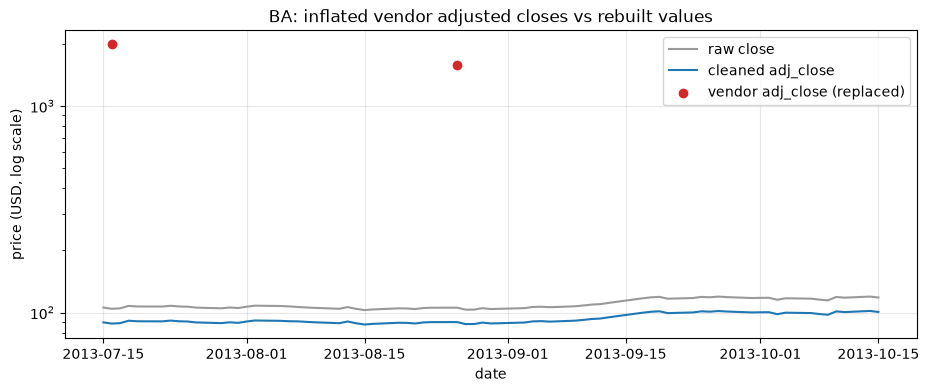

In [20]:
# Visual check: vendor vs rebuilt adjusted close for BA around one of the inflated values.
ba = clean[(clean["ticker"] == "BA") & clean["ts"].between("2013-07-15", "2013-10-15")]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ba["ts"], ba["close"], color="0.6", label="raw close")
ax.plot(ba["ts"], ba["adj_close"], color="tab:blue", label="cleaned adj_close")
replaced = ba["repair_flags"].str.contains("adj_close_replaced")
ax.scatter(ba.loc[replaced, "ts"], ba.loc[replaced, "adj_close_vendor"], color="tab:red", zorder=3,
           label="vendor adj_close (replaced)")
ax.set_yscale("log")
ax.set(title="BA: inflated vendor adjusted closes vs rebuilt values", xlabel="date", ylabel="price (USD, log scale)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### Quarantined rows

These are kept in a separate table with the reason, not silently dropped.

In [21]:
display(result.quarantine[["raw_rowid", "ticker", "ts", "open", "high", "low", "close", "adj_close", "volume", "quarantine_reason"]])

,raw_rowid,ticker,ts,open,high,low,close,adj_close,volume,quarantine_reason
0,287344,CVX,1962-01-02,0.0,3.30000,3.24000,3.30000,0.335750,105840.0,invalid raw OHLC with no earlier valid row to ...
1,350809,JNJ,1962-01-02,0.0,0.22338,0.22222,0.22338,0.064012,0.0,invalid raw OHLC with no earlier valid row to ...
2,224791,MCD,1966-07-05,0.0,0.27366,0.26749,0.26955,0.118090,388800.0,invalid raw OHLC with no earlier valid row to ...
3,364569,MRK,1962-01-02,0.0,0.39703,0.39317,0.39537,0.068447,633830.0,invalid raw OHLC with no earlier valid row to ...
4,99638,PG,1962-01-02,0.0,1.44000,1.42000,1.43000,0.259300,192000.0,invalid raw OHLC with no earlier valid row to ...


### The same repairs on injected examples

The real data has no mid-series impossible prices, missing volume, or all-missing rows, so here is the
behavior on a small example: an all-missing row (dropped), a close above the high (row carried forward),
an unknown volume (0 + flag), and a leading nonpositive open (quarantined).

In [22]:
repair_demo = pd.DataFrame({
    "ts": ["2024-01-02", "2024-01-03", "2024-01-04", "2024-01-05", "2024-01-08"], "ticker": "XYZ",
    "open": [0.0, 10.2, np.nan, 10.4, 10.5], "high": [10.5, 10.6, np.nan, 10.8, 10.9],
    "low": [9.8, 10.0, np.nan, 10.1, 10.2], "close": [10.3, 10.4, np.nan, 12.0, 10.6],
    "adj_close": [5.15, 5.2, np.nan, 6.0, 5.3], "volume": [1000, np.nan, 500, 900, 950],
})
demo_ref = repair_demo.assign(adj_close=repair_demo["close"] / 2).dropna(subset=["close"])
demo_result = hc.clean_ohlc(repair_demo, demo_ref)
display(demo_result.row_accounting())
display(demo_result.clean[["ts", "open", "high", "low", "close", "adj_close", "volume", "repair_flags"]])
display(demo_result.quarantine[["ts", "open", "quarantine_reason"]])

,rows
raw input,5
exact duplicates removed,0
all-missing OHLC removed,1
quarantined,1
retained in ohlc_hw_cleaned,3


,ts,open,high,low,close,adj_close,volume,repair_flags
0,2024-01-03,10.2,10.6,10.0,10.4,5.2,0,volume_missing_filled_0
1,2024-01-05,10.2,10.6,10.0,10.4,5.2,900,ohlc_forward_filled_from_previous_row
2,2024-01-08,10.5,10.9,10.2,10.6,5.3,950,


,ts,open,quarantine_reason
0,2024-01-02,0.0,invalid raw OHLC with no earlier valid row to ...


For **confirmed** data errors in the middle of a series, `interpolate_confirmed_errors` interpolates the
price row between the valid neighbours (never extrapolating at the ends). Example with one bad day:

In [23]:
interp_demo = hc.prepare_raw(repair_demo.iloc[1:].assign(open=[10.2, 10.3, 10.4, 10.5], high=[10.6, 10.7, 10.8, 10.9],
                                                         low=[10.0, 10.1, 10.1, 10.2], close=[10.4, 10.5, 99.0, 10.6],
                                                         adj_close=[5.2, 5.25, 49.5, 5.3]))
fixed, unresolved = hc.interpolate_confirmed_errors(interp_demo, interp_demo["close"].eq(99.0))
display(fixed[["ts", "open", "high", "low", "close", "adj_close", "repair_flags"]])

,ts,open,high,low,close,adj_close,repair_flags
1,2024-01-03,10.2,10.6,10.00,10.40,5.200,
2,2024-01-04,10.3,10.7,10.10,10.50,5.250,
3,2024-01-05,10.4,10.8,10.15,10.55,5.275,prices_interpolated_confirmed_error
4,2024-01-08,10.5,10.9,10.20,10.60,5.300,


### Investigating extreme returns (>3σ)

For each flagged day we look for **evidence**, rather than assuming a cause:

* **Vendor typo?** A return uses two closes (today and the previous day). If both match the reference
  `ohlc` table, the vendor did not mistype them: `return_outlier_class = matches_reference`. Otherwise it
  is `differs_from_reference`, a candidate vendor error. Matching the reference does **not** prove a price
  is real — the reference can contain the same bad print — so extreme cases are also inspected directly.
* **Stock split?** An unadjusted split would show as a permanent raw-close drop of roughly −50%
  (2-for-1) or more. We check two publicly announced AAPL splits (7-for-1 effective 2014-06-09, 4-for-1
  effective 2020-08-31) and then inspect every raw return of −40% or worse with its neighbouring days.
* **Market-wide move?** Many tickers flagged on the same date points to a market-wide event. We do not
  attribute specific news without a source.

In [24]:
inv = clean.copy()
inv["raw_return"] = hc.simple_returns(inv, "close")
flagged = inv[inv["return_outlier"]]
print(f"Flagged days: {len(flagged):,}")
display(flagged["return_outlier_class"].value_counts().rename("days").to_frame())

Flagged days: 5,057


,days
return_outlier_class,
matches_reference,5057


In [25]:
split_dates = pd.to_datetime(["2014-06-06", "2014-06-09", "2020-08-28", "2020-08-31"])
display(inv[(inv["ticker"] == "AAPL") & inv["ts"].isin(split_dates)][["ticker", "ts", "close", "adj_close", "raw_return"]])

,ticker,ts,close,adj_close,raw_return
8439,AAPL,2014-06-06,23.06,20.37,-0.002595
8440,AAPL,2014-06-09,23.43,20.70,0.016045
10008,AAPL,2020-08-28,124.81,121.97,-0.001600
10009,AAPL,2020-08-31,129.04,126.10,0.033892


AAPL's raw close moves less than 4% across both split dates, so this table's "raw" OHLC is **already
split-adjusted** for these splits; `adj_close` additionally reflects dividends. Now every raw return of
−40% or worse, shown with the day before and the day after:

In [26]:
inv["adj_return"] = hc.simple_returns(inv, "adj_close")
context_cols = ["ticker", "ts", "open", "close", "adj_close", "volume", "raw_return", "adj_return"]
extreme_positions = np.flatnonzero(inv["raw_return"].le(-0.4).to_numpy())
for pos in extreme_positions:
    display(inv.iloc[pos - 1:pos + 2][context_cols]
            .style.format({"raw_return": "{:+.1%}", "adj_return": "{:+.1%}", "volume": "{:,.0f}"}))

,ticker,ts,open,close,adj_close,volume,raw_return,adj_return
4998,AAPL,2000-09-28 00:00:00,0.880580,0.955360,0.806770,"980,466,003",+9.3%,+9.3%
4999,AAPL,2000-09-29 00:00:00,0.503350,0.459820,0.388310,"3,128,875,900",-51.9%,-51.9%
5000,AAPL,2000-10-02 00:00:00,0.473210,0.433040,0.365690,"2,424,791,671",-5.8%,-5.8%


,ticker,ts,open,close,adj_close,volume,raw_return,adj_return
213784,MCD,1967-12-29 00:00:00,0.738680,0.709880,0.311000,"1,093,500",-3.9%,-3.9%
213785,MCD,1968-01-02 00:00:00,0.174900,0.174900,0.075921,"6,755,143",-75.4%,-75.6%
213786,MCD,1968-01-03 00:00:00,0.175670,0.175670,0.076256,"3,839,207",+0.4%,+0.4%


,ticker,ts,open,close,adj_close,volume,raw_return,adj_return
318327,TRV,1976-10-28 00:00:00,9.220000,9.220000,3.210000,0,+100.0%,+227.4%
318328,TRV,1976-10-29 00:00:00,4.690000,4.690000,0.997070,"79,200",-49.1%,-68.9%
318329,TRV,1976-11-01 00:00:00,4.660000,4.660000,0.990430,"59,200",-0.6%,-0.7%


,ticker,ts,open,close,adj_close,volume,raw_return,adj_return
318868,TRV,1978-12-20 00:00:00,8.030000,8.030000,2.800000,0,+99.8%,+208.9%
318869,TRV,1978-12-21 00:00:00,4.090000,4.090000,0.924090,"105,600",-49.1%,-67.0%
318870,TRV,1978-12-22 00:00:00,4.090000,4.090000,0.936960,"91,200",+0.0%,+1.4%


,ticker,ts,open,close,adj_close,volume,raw_return,adj_return
319533,TRV,1981-08-10 00:00:00,12.060000,12.060000,4.200000,0,+100.0%,+167.5%
319534,TRV,1981-08-11 00:00:00,6.030000,6.030000,1.570000,"24,800",-50.0%,-62.6%
319535,TRV,1981-08-12 00:00:00,6.130000,6.130000,1.590000,"267,200",+1.7%,+1.3%


Evidence and stated uncertainty for these five days:

* **AAPL 2000-09-29 (−52%)** — a permanent drop on roughly three times the previous day's volume, in both
  raw and adjusted prices. Consistent with a genuine market move; kept.
* **MCD 1968-01-02 (−75%)** — a *permanent* ~4× drop in both raw and adjusted prices on heavy volume. This
  pattern is consistent with a split that was never adjusted for, but we have no corporate-action record
  to confirm it. Kept and flagged; outside the 2024 analysis window.
* **TRV 1976-10-28, 1978-12-20, 1981-08-10** — one-day price spikes, examined in detail below (the
  −49%/−50% rows above are the reversals the day after each spike).

#### The three TRV spikes: kept unchanged and flagged

Each spike day is shown with its neighbours, next to the same dates in the reference `ohlc` table:

In [27]:
trv = inv[inv["ticker"] == "TRV"].reset_index(drop=True)
spike_dates = pd.to_datetime(["1976-10-28", "1978-12-20", "1981-08-10"])
spike_pos = trv.index[trv["ts"].isin(spike_dates)]
window = sorted(set(spike_pos - 1) | set(spike_pos) | set(spike_pos + 1))
trv_context = trv.loc[window, ["ts", "open", "close", "adj_close", "volume", "raw_return",
                               "return_outlier", "zero_volume_flag", "repair_flags"]]
trv_reference = (reference[reference["ticker"] == "TRV"]
                 .assign(ts=lambda d: pd.to_datetime(d["ts"], format="%Y-%m-%d"))
                 [["ts", "close", "adj_close", "volume"]]
                 .rename(columns=lambda c: c if c == "ts" else f"ref_{c}"))
trv_context = trv_context.merge(trv_reference, on="ts", how="left")
display(trv_context.style.format({"raw_return": "{:+.1%}", "volume": "{:,.0f}", "ref_volume": "{:,.0f}"}))
same_as_reference = (np.isclose(trv_context["close"], trv_context["ref_close"])
                     & np.isclose(trv_context["adj_close"], trv_context["ref_adj_close"])
                     & trv_context["volume"].eq(trv_context["ref_volume"]))
print("Rows identical to the reference (close, adj_close, volume):", f"{same_as_reference.sum()} of {len(trv_context)}")

,ts,open,close,adj_close,volume,raw_return,return_outlier,zero_volume_flag,repair_flags,ref_close,ref_adj_close,ref_volume
0,1976-10-27 00:00:00,4.610000,4.610000,0.980460,"230,400",+2.4%,False,False,adj_close_replaced_with_reference_factor,4.610000,0.980460,"230,400"
1,1976-10-28 00:00:00,9.220000,9.220000,3.210000,0,+100.0%,True,True,adj_close_filled_from_reference_factor,9.220000,3.210000,0
2,1976-10-29 00:00:00,4.690000,4.690000,0.997070,"79,200",-49.1%,True,False,,4.690000,0.997070,"79,200"
3,1978-12-19 00:00:00,4.020000,4.020000,0.906450,"72,000",+0.0%,False,False,,4.020000,0.906450,"72,000"
4,1978-12-20 00:00:00,8.030000,8.030000,2.800000,0,+99.8%,True,True,,8.030000,2.800000,0
5,1978-12-21 00:00:00,4.090000,4.090000,0.924090,"105,600",-49.1%,True,False,,4.090000,0.924090,"105,600"
6,1981-08-07 00:00:00,6.030000,6.030000,1.570000,"264,800",-0.5%,False,False,,6.030000,1.570000,"264,800"
7,1981-08-10 00:00:00,12.060000,12.060000,4.200000,0,+100.0%,True,True,,12.060000,4.200000,0
8,1981-08-11 00:00:00,6.030000,6.030000,1.570000,"24,800",-50.0%,True,False,,6.030000,1.570000,"24,800"


Rows identical to the reference (close, adj_close, volume): 9 of 9


**Why they appear erroneous.** On each spike day the close is almost exactly double the previous close
(+100.0%, +99.8%, +100.0%), open equals close, the reported volume is **0**, and on the next trading day
the price returns to its earlier level on normal volume. A genuine doubling would be expected to trade
on heavy volume and not to reverse completely overnight; a new price on a no-trade day points to a
stale or mis-scaled quote. The exact cause (for example, a price quoted on a different share basis) is
**not verified**.

**Why the reference table does not independently confirm the correct prices.** The supplied `ohlc` table
contains the *same* close, adjusted close and volume for these rows, so both tables carry the same
values from a common source. Agreement shows only that `ohlc_hw` was copied faithfully; it is not a
second, independent observation of the price. The reference adjusted close spikes as well, so its
adjustment factor offers no correction either. Without an independent source, the true price on these
dates is unknown.

**Why no interpolation was applied.** The assignment calls for interpolating only **confirmed** data
errors. Here the evidence is a pattern, not a confirmation, and interpolation would replace an observed
value with an estimate whose accuracy cannot be checked. The rows are therefore kept **unchanged**,
remain flagged (`return_outlier` on the spike and reversal days; `zero_volume_flag` on the spike days),
and are documented here. All three lie decades before the Part 2/3 analysis window, so this choice does
not affect any report. If an independent source later confirmed them as errors,
`hc.interpolate_confirmed_errors` (demonstrated above) would repair them between the valid neighbouring
days.

In [28]:
per_date = flagged.groupby("ts")["ticker"].nunique().sort_values(ascending=False).rename("tickers flagged")
display(per_date.head(8).to_frame())
display(flagged.reindex(flagged["raw_return"].abs().sort_values(ascending=False).index).head(8)
        [["ticker", "ts", "close", "raw_return", "return_outlier_class"]]
        .style.format({"raw_return": "{:+.1%}"}))

,tickers flagged
ts,
2020-03-12,29
2020-03-16,28
2008-10-28,28
2008-10-13,26
2020-03-24,25
1987-10-19,24
2008-12-01,22
2008-10-15,22


,ticker,ts,close,raw_return,return_outlier_class
319533,TRV,1981-08-10 00:00:00,12.060000,+100.0%,matches_reference
318327,TRV,1976-10-28 00:00:00,9.220000,+100.0%,matches_reference
318868,TRV,1978-12-20 00:00:00,8.030000,+99.8%,matches_reference
213785,MCD,1968-01-02 00:00:00,0.174900,-75.4%,matches_reference
4999,AAPL,2000-09-29 00:00:00,0.459820,-51.9%,matches_reference
319534,TRV,1981-08-11 00:00:00,6.030000,-50.0%,matches_reference
318328,TRV,1976-10-29 00:00:00,4.690000,-49.1%,matches_reference
318869,TRV,1978-12-21 00:00:00,4.090000,-49.1%,matches_reference


**Decision:** every flagged return is `matches_reference` (no vendor typo). On the most-flagged dates,
20 or more of the 30 tickers were flagged together, which is consistent with market-wide events. Flags are
kept (`return_outlier`, `return_outlier_class`) rather than deleted, because removing real extreme days
would understate risk in Part 2. Nothing is interpolated: the only suspicious cases (the TRV zero-volume
spikes, the MCD level shift) are documented above with their uncertainty, and none falls inside the
Part 2/3 analysis window.

## Validation

In [29]:
validation = hc.validate_clean(clean)
display(validation)
hc.assert_valid(clean)
print("All required checks passed on", f"{len(clean):,}", "retained rows.")

,check,failures,passed
0,missing ticker,0,True
1,missing or unparseable ts,0,True
2,missing price,0,True
3,non-finite price,0,True
4,nonpositive price,0,True
5,OHLC bounds violated,0,True
6,"missing, non-finite or negative volume",0,True
7,"duplicate (ticker, ts) keys",0,True


All required checks passed on 368,246 retained rows.


**Re-run the diagnosis on the cleaned data.** No high-severity issue may remain. The quarantined first
rows now show up as absent sessions relative to the reference calendar — expected, and documented.

In [30]:
after_sessions = hc.find_missing_sessions(clean, reference_keys)
after_report = hc.detect_issues(clean, after_sessions, factors)
comparison = pd.concat({
    "before": quality_report.groupby(["severity", "issue_type"]).size(),
    "after": after_report.groupby(["severity", "issue_type"]).size(),
}, axis=1).fillna(0).astype(int)
display(comparison)
assert not after_report["severity"].eq("high").any(), "high-severity issues remain"

before  after
severity issue_type                       
high     adj_close_mismatch   10417      0
         nonpositive_price        5      0
         open_outside_range       5      0
low      exact_duplicate      29460      0
         return_outlier        5056   5057
         zero_volume             75     74
medium   missing_adj_close    18374      0
         missing_session          0      5

### Before / after statistics

In [31]:
cols = ["count", "mean", "min", "max"]
before_after = pd.concat({
    "before (raw ohlc_hw)": raw[hc.VALUE_COLS].describe().T[cols],
    "after (ohlc_hw_cleaned)": clean[hc.VALUE_COLS].describe().T[cols],
}, axis=1)
display(before_after.style.format("{:,.4g}"))
print(f"Tickers: {raw['ticker'].nunique()} raw labels -> {clean['ticker'].nunique()} tickers")

Tickers: 150 raw labels -> 30 tickers


## Save to the working database

Three tables are written to `data/data.db` (raw `ohlc_hw` and `ohlc` are untouched):

* `ohlc_hw_cleaned` — retained rows with audit columns (`ticker_original`, `adj_close_vendor`,
  `repair_flags`, `zero_volume_flag`, `return_outlier`, `return_outlier_class`, `raw_rowid`); `ts` stored as
  ISO `YYYY-MM-DD` so SQL date filters work; a unique index enforces one row per `(ticker, ts)`.
* `ohlc_hw_quality_report` — the pre-repair Data Quality Report.
* `ohlc_hw_quarantine` — rows not retained, with `quarantine_reason`.

In [32]:
quarantine_cols = ["raw_rowid", "ticker", "ticker_original", "ts", *hc.VALUE_COLS, "repair_flags", "quarantine_reason"]
tables = {
    "ohlc_hw_cleaned": hc.to_sql_frame(clean, hc.CLEAN_COLUMNS),
    "ohlc_hw_quality_report": hc.to_sql_frame(quality_report, hc.REPORT_COLUMNS),
    "ohlc_hw_quarantine": hc.to_sql_frame(result.quarantine, quarantine_cols),
}
with closing(sqlite3.connect(DB_PATH)) as conn:
    with conn:  # one transaction: all tables are written or none
        for name, frame in tables.items():
            frame.to_sql(name, conn, if_exists="replace", index=False)
        conn.execute("CREATE UNIQUE INDEX IF NOT EXISTS ix_ohlc_hw_cleaned_ticker_ts ON ohlc_hw_cleaned (ticker, ts)")
print({name: len(frame) for name, frame in tables.items()})

{'ohlc_hw_cleaned': 368246, 'ohlc_hw_quality_report': 63392, 'ohlc_hw_quarantine': 5}


### Read back and verify

In [33]:
with closing(read_only(DB_PATH)) as conn:
    stored = pd.read_sql_query("SELECT * FROM ohlc_hw_cleaned", conn)
    stored_counts = {name: int(pd.read_sql_query(f"SELECT COUNT(*) AS n FROM {name}", conn)["n"].iloc[0])
                     for name in tables}
    raw_after = pd.read_sql_query("SELECT rowid AS raw_rowid, * FROM ohlc_hw", conn)
    window = pd.read_sql_query(
        "SELECT COUNT(*) AS n, MIN(ts) AS first, MAX(ts) AS last FROM ohlc_hw_cleaned "
        "WHERE ticker = ? AND ts BETWEEN ? AND ?", conn, params=("AAPL", "2024-06-01", "2024-11-30"))

assert stored_counts == {name: len(frame) for name, frame in tables.items()}
assert stored["ts"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all(), "ts must be ISO dates"
hc.assert_valid(stored.assign(ts=pd.to_datetime(stored["ts"], format="%Y-%m-%d")))
assert int(pd.util.hash_pandas_object(raw_after, index=False).sum()) == raw_fingerprint, "ohlc_hw changed!"
print("Stored row counts:", stored_counts)
print("Stored cleaned table passes validation; raw ohlc_hw unchanged.")
print("SQL date filter check (AAPL, 2024-06-01..2024-11-30):")
display(window)

Stored row counts: {'ohlc_hw_cleaned': 368246, 'ohlc_hw_quality_report': 63392, 'ohlc_hw_quarantine': 5}
Stored cleaned table passes validation; raw ohlc_hw unchanged.
SQL date filter check (AAPL, 2024-06-01..2024-11-30):


,n,first,last
0,97,2024-06-03,2024-10-18


## Summary of decisions

* **Tickers** were normalized (HTML markup, whitespace, case) before any grouping; the original label is
  kept in `ticker_original`.
* **Exact duplicates** were removed; **conflicting keys** would be quarantined (none occurred).
* **Missing sessions** were checked against each ticker's `ohlc` calendar: none missing.
* **Adjusted close** was rebuilt from the same-date reference factor where missing or inconsistent with
  the raw close; vendor values are preserved in `adj_close_vendor`.
* **Impossible raw prices** are repaired by carrying the previous valid price row forward; the only cases
  were five leading `open = 0` rows, which have nothing to carry and are quarantined.
* **3σ returns** are flagged and kept. All match the reference closes (no vendor typos). Three TRV
  zero-volume one-day spikes (1976–1981) look like bad prints but are not independently confirmed (the
  reference carries the same values), so they are kept unchanged, flagged and not interpolated. An MCD
  1968 drop may be an unadjusted split. All lie outside the analysis window.
* **Zero volume** is kept and flagged; unknown volume would be filled with 0 and flagged separately.
* Every retained row passes the required validation, every raw row is accounted for, and the raw table is
  unchanged.

Next: `02_stock_report_template.ipynb` reads `ohlc_hw_cleaned`.